<a href="https://colab.research.google.com/github/ob-s/FedShield/blob/main/Baseline_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Loads datasets from drive folder
file_path = '/content/drive/MyDrive/Malware_Project/MalMem2022.csv'
df = pd.read_csv(file_path)

print(f"Total dataset size: {len(df)} items")

Total dataset size: 58596 items


In [3]:
# The dataset has a 'Class' column (Benign vs Malware)
#'Category' column detailing specific malware types (Spyware, Ransomware, etc.)
# For deep learning classifier, only the binary 'Class' column is needed.
if 'Category' in df.columns:
    df = df.drop(columns=['Category'])

# Convert string labels to binary integers (0 for Benign, 1 for Malware)
df['Class'] = df['Class'].apply(lambda x: 0 if x == 'Benign' else 1)

# Separate features (X) and labels (y)
X = df.drop(columns=['Class'])
y = df['Class']

# Drop non-numeric columns (such as sample names, hashes, or text identifiers)
X = X.select_dtypes(include=[np.number])

# Execute the 80/20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set (80%): {X_train.shape[0]} items")
print(f"Testing set (20%): {X_test.shape[0]} items")

# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training set (80%): 46876 items
Testing set (20%): 11720 items


In [4]:
# Build the baseline classifier using TensorFlow
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

# Compile the model
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])

# Train the model
print("Training the baseline model...")
history = model.fit(X_train_scaled, y_train,
                    epochs=15,
                    batch_size=64,
                    validation_split=0.2)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training the baseline model...
Epoch 1/15
586/586 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9923 - loss: 0.0402 - precision: 0.9921 - recall: 0.9925 - val_accuracy: 0.9986 - val_loss: 0.0054 - val_precision: 0.9978 - val_recall: 0.9993
Epoch 2/15
586/586 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9984 - loss: 0.0093 - precision: 0.9983 - recall: 0.9986 - val_accuracy: 0.9988 - val_loss: 0.0044 - val_precision: 0.9983 - val_recall: 0.9993
Epoch 3/15
586/586 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9990 - loss: 0.0041 - precision: 0.9988 - recall: 0.9991 - val_accuracy: 0.9990 - val_loss: 0.0039 - val_precision: 0.9980 - val_recall: 1.0000
Epoch 4/15
586/586 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9990 - loss: 0.0035 - precision: 0.9989 - recall: 0.9991 - val_accuracy: 0.9990 - val_loss: 0.0034 - val_precision: 0.9980 - val_recall: 1.0000
Epoch 5/15
586/586 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9994 - loss: 0.0030 - precision: 0.9990 - recall: 0.9997 - val

In [5]:
# Evaluate baseline performance on unseen test data
eval_results = model.evaluate(X_test_scaled, y_test, verbose=1)

print("\n--- Final Baseline Test Results ---")
print(f"Loss:      {eval_results[0]:.4f}")
print(f"Accuracy:  {eval_results[1] * 100:.2f}%")
print(f"Precision: {eval_results[2] * 100:.2f}%")
print(f"Recall:    {eval_results[3] * 100:.2f}%")

# Calculate F1-Score for academic documentation
precision = eval_results[2]
recall = eval_results[3]
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
print(f"F1-Score:  {f1_score * 100:.2f}%")

367/367 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9997 - loss: 6.1041e-04 - precision: 0.9997 - recall: 0.9998

--- Final Baseline Test Results ---
Loss:      0.0006
Accuracy:  99.97%
Precision: 99.97%
Recall:    99.98%
F1-Score:  99.97%


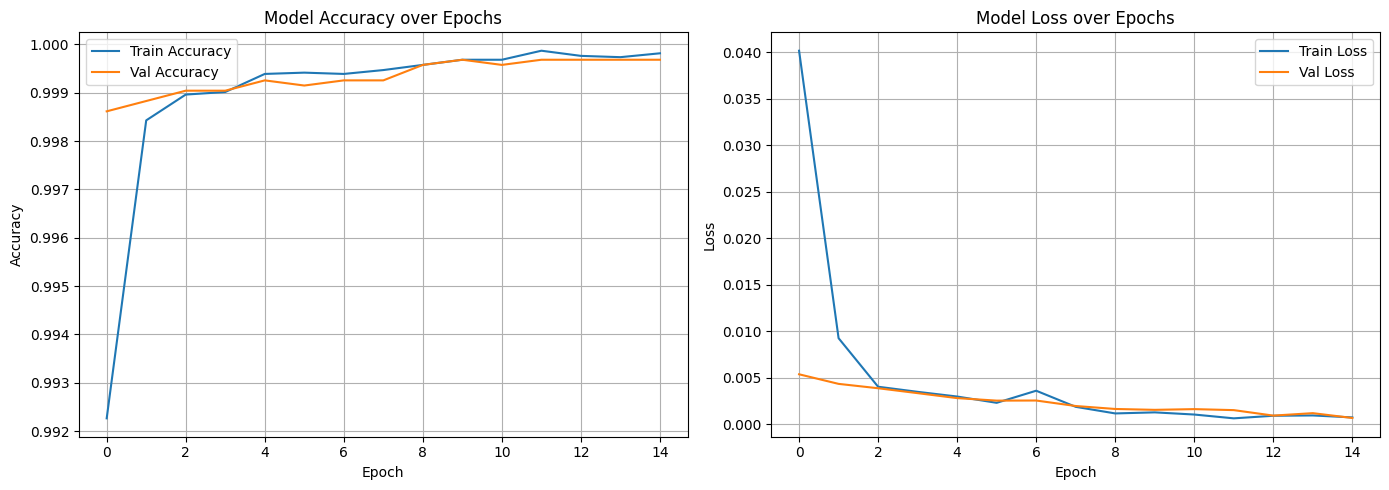

In [6]:
import matplotlib.pyplot as plt

# Plot Training & Validation Accuracy and Loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
ax1.plot(history.history['accuracy'], label='Train Accuracy')
ax1.plot(history.history['val_accuracy'], label='Val Accuracy')
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Loss plot
ax2.plot(history.history['loss'], label='Train Loss')
ax2.plot(history.history['val_loss'], label='Val Loss')
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.savefig('baseline_training_curves.png')
plt.show()

In [12]:
!pip install -U "flwr[simulation]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.7/73.7 MB 11.4 MB/s eta 0:00:00


In [8]:
# Split the training data evenly to simulate independent VM datasets
split_index = len(X_train_scaled) // 2

X_vm1, y_vm1 = X_train_scaled[:split_index], y_train.iloc[:split_index]
X_vm2, y_vm2 = X_train_scaled[split_index:], y_train.iloc[split_index:]

print(f"VM 1 Local Training Data: {X_vm1.shape[0]} items")
print(f"VM 2 Local Training Data: {X_vm2.shape[0]} items")

VM 1 Local Training Data: 23438 items
VM 2 Local Training Data: 23438 items


In [10]:
import flwr as fl

class MalwareDetectionClient(fl.client.NumPyClient):
    def __init__(self, X_local, y_local):
        self.X_local = X_local
        self.y_local = y_local

        # The VM initializes its own local architecture
        self.local_model = Sequential([
            Dense(64, activation='relu', input_shape=(self.X_local.shape[1],)),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(1, activation='sigmoid')
        ])
        self.local_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    def get_parameters(self, config):
        # Extract weights to send back to the Host Machine
        return self.local_model.get_weights()

    def fit(self, parameters, config):
        # 1. Receive global weights from Host Machine
        self.local_model.set_weights(parameters)

        # 2. Train on the VM's local data
        self.local_model.fit(self.X_local, self.y_local, epochs=3, batch_size=64, verbose=0)

        # 3. Send updated weights and data size back to the Host
        return self.local_model.get_weights(), len(self.X_local), {}

    def evaluate(self, parameters, config):
        self.local_model.set_weights(parameters)
        loss, accuracy = self.local_model.evaluate(self.X_local, self.y_local, verbose=0)
        return loss, len(self.X_local), {"accuracy": accuracy}

In [13]:
# Function to assign datasets to our simulated VMs
def client_fn(cid: str) -> fl.client.Client:
    if cid == "0":
        return MalwareDetectionClient(X_vm1, y_vm1).to_client()
    else:
        return MalwareDetectionClient(X_vm2, y_vm2).to_client()

# Define the Host Machine's Aggregation Strategy (FedAvg)
strategy = fl.server.strategy.FedAvg(
    fraction_fit=1.0,  # Train on all available VMs
    fraction_evaluate=1.0,
    min_fit_clients=2, # Require both VMs to participate
    min_available_clients=2
)

# Start the Central Server simulation
print("Host Machine starting Federated Training with 2 Client VMs...")
fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=2,
    config=fl.server.ServerConfig(num_rounds=5), # Run 5 communication rounds
    strategy=strategy,
)

Host Machine starting Federated Training with 2 Client VMs...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          

History (loss, distributed):
	round 1: 0.006020145141519606
	round 2: 0.0017588905757293105
	round 3: 0.001137599116191268
	round 4: 0.0006691708113066852
	round 5: 0.0005393325263867155

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
